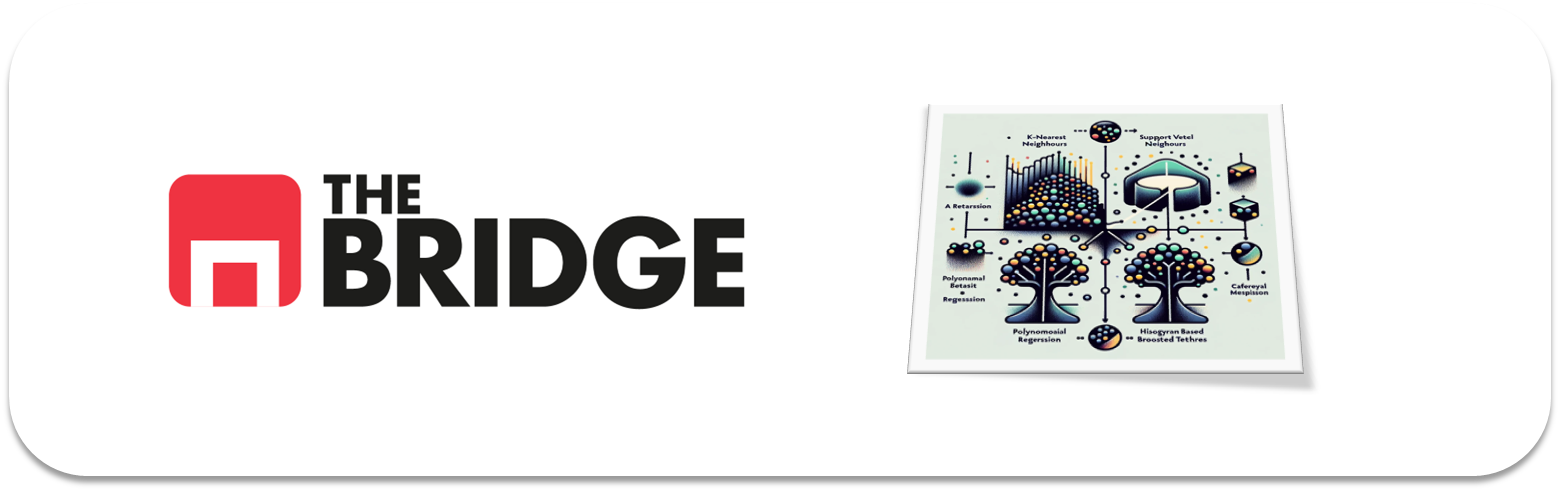

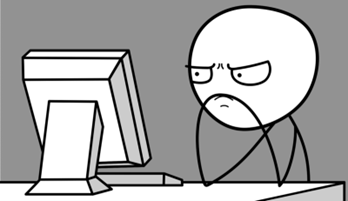

Para ejercitarte y afianzar lo aprendido sobre **Otros Modelos de aprendizaje supervisado**, completa los siguientes ejercicios. Recuerda que necesitarás datos que están en el directorio `data` de la raíz de la unidad (`../data`)
  
Las soluciones las tienes ya; intenta no mirarlas de primeras pero no dejes de hacerlo cuando hayas terminado por si te pudieran aportar.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook

In [1]:
import bootcampviztools as bt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


%matplotlib inline
plt.rcParams['figure.figsize'] = (16, 9)
plt.style.use('ggplot')

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler



## KNN

Vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating (ojo, no el sentimiento), en función del sentimiento del comentario y su valor y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

### Ejercicio 1

Lee el archivo de entrada "reviews_sentiment.csv" y carga su contenido en un dataframe. Muestra sus primeras líneas, su información general y define una variable "target" asignándole el nombre de la columna que contenga el target del problema. 

In [2]:
df = pd.read_csv("../data/reviews_sentiment.csv", sep=";")
df.head(10)

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784
5,Buena,Nada del otro mundo pero han mejorado mucho,8,positive,negative,1,-0.720443
6,De gran ayuda,"Lo malo q necesita de …,pero la app es muy buena",23,positive,negative,1,-0.726825
7,Muy buena,"Estaba más acostumbrado al otro diseño, pero e...",16,positive,negative,1,-0.736769
8,Ta to guapa.,Va de escándalo,21,positive,negative,1,-0.765284
9,Se han corregido,Han corregido muchos fallos pero el diseño es ...,13,negative,negative,1,-0.797961


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    object 
 1   Review Text     257 non-null    object 
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    object 
 4   textSentiment   257 non-null    object 
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 14.2+ KB


*Respecto a la variable target hay que tener en cuenta que no nos están pidiendo el sentimiento en términos de positivo o negativo sino predecir el rating...*

In [4]:
target = "Star Rating" 

### Ejercicio 2

Muestra la distribución del target y coméntala brevemente.

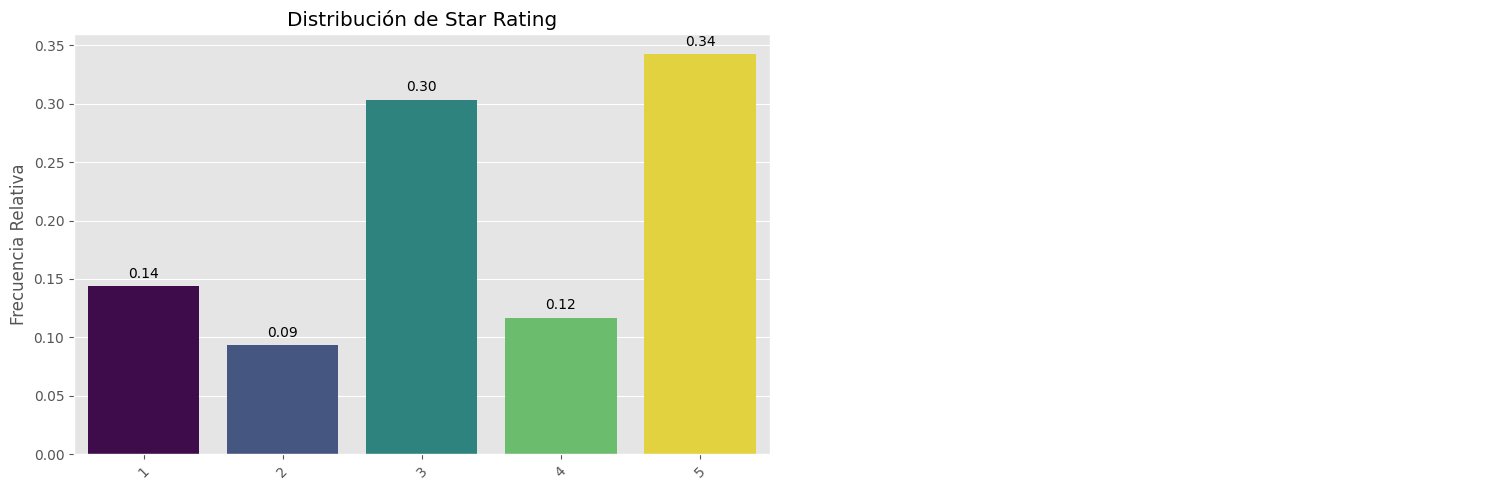

In [5]:
bt.pinta_distribucion_categoricas(df,[target], mostrar_valores= True, relativa= True)

*Es un dataset desbalanceado, en el que puede que haya que hacer algún tipo de transformación para poder obtener modelos con mejores prestaciones*

### Ejercicio 3

Deshazte de la columna "titleSentiment" que tiene nulos y no vamos a emplearla.

In [6]:
df.drop("titleSentiment", axis = 1, inplace = True)

### Ejercicio 4

Haz el split en train y test.

In [7]:
train_set, test_set = train_test_split(df, test_size= 0.2, random_state= 42)

### Ejercicio 5

Muestra la descripción de las variables que consideres numéricas (justificando tu elección) y sus histogramas. ¿Hay que aplicar alguna transformación o tratamiento? (Recuerda que vamos a emplear un KNN)

*Consideramos como realmente numéricas "wordcount", en cuyo caso no debes fijarte solo en su rango actual sino en el hecho de que las reviews pueden tener tantas palabras como quiera el que las escriba, y "sentimentValue", esta es claramente numérica continua*

In [8]:
features_num = ["wordcount","sentimentValue"]

In [9]:
train_set[features_num].describe()

,wordcount,sentimentValue
count,205.000000,205.000000
mean,11.209756,0.400269
std,12.875341,0.871054
min,1.000000,-1.780889
25%,3.000000,-0.106498
50%,7.000000,0.244713
75%,15.000000,0.813521
max,103.000000,3.264579


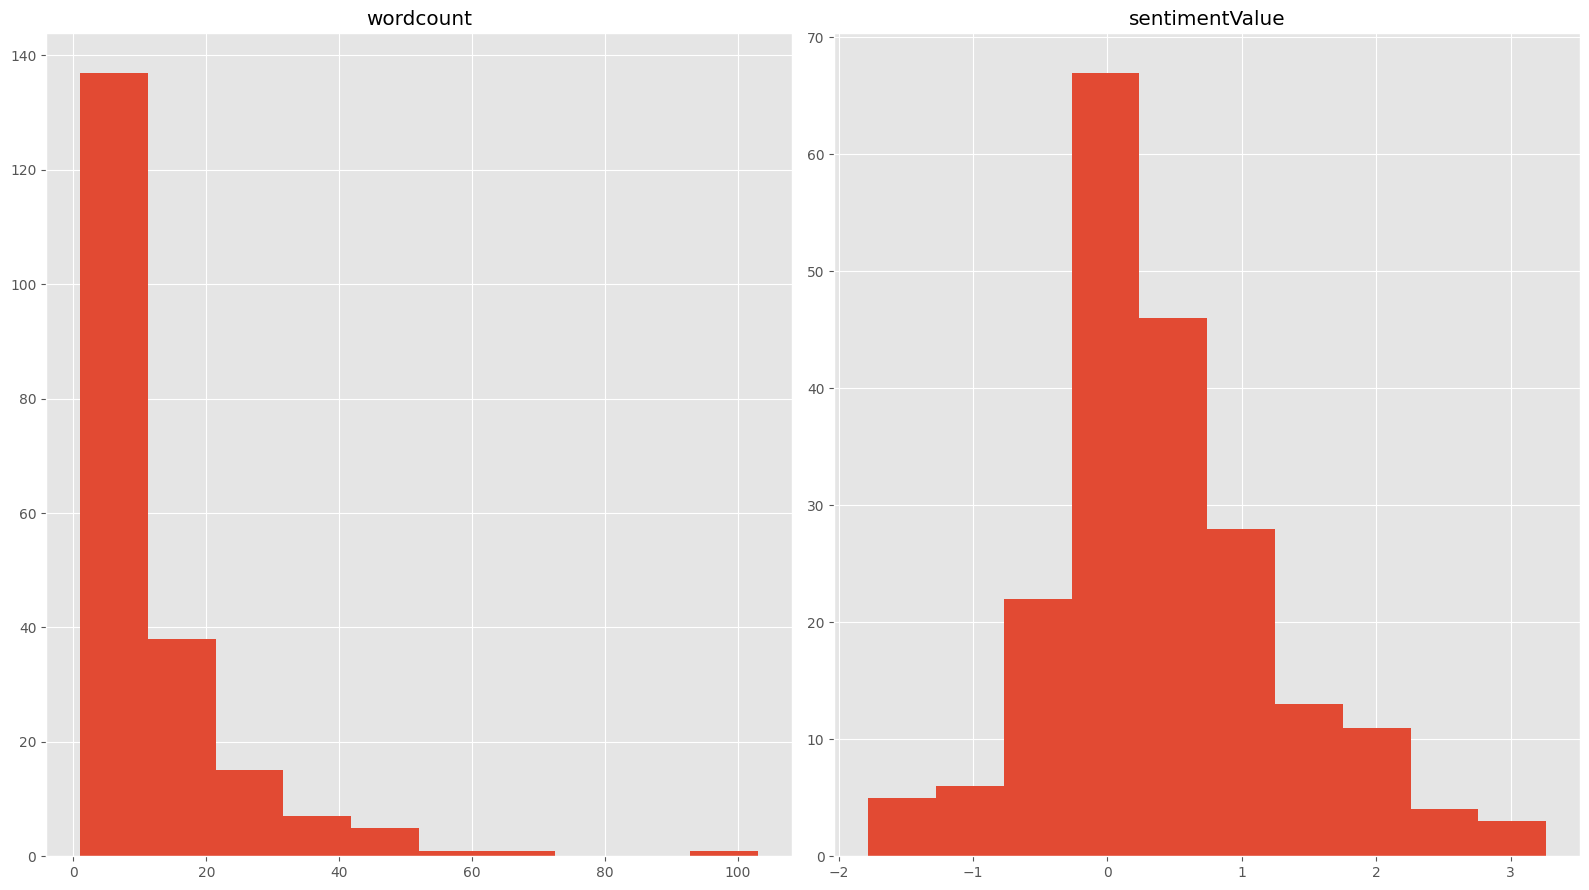

In [10]:
train_set[features_num].hist()
plt.tight_layout();

*En ambos casos tendremos que escalar ya que los rangos son muy diversos y KNN es un algoritmo muy sensible a escalas ya que se basa en el cálculo de distancias entre instancias, considerando el conjunto de features como un vector. Además en el caso de `wordcount` una transformación, tipo logarítmica, no le vendría nada mal para "normalizarla" un poco*

### Ejercicio 6

Muestra la distribución frecuencial de las variables que consideres categóricas. ¿Habría que hacerles algún tipo de tratamiento?

*Creamos nuestra lista de features categóricas, lo primero*

In [11]:
features_cat = ["textSentiment"]

*Usamos nuestra biblioteca de herramientas visuales, aunque puedes hacerlo "a mano" con el countplot o el barplot de alguna de las librerías que conoces*

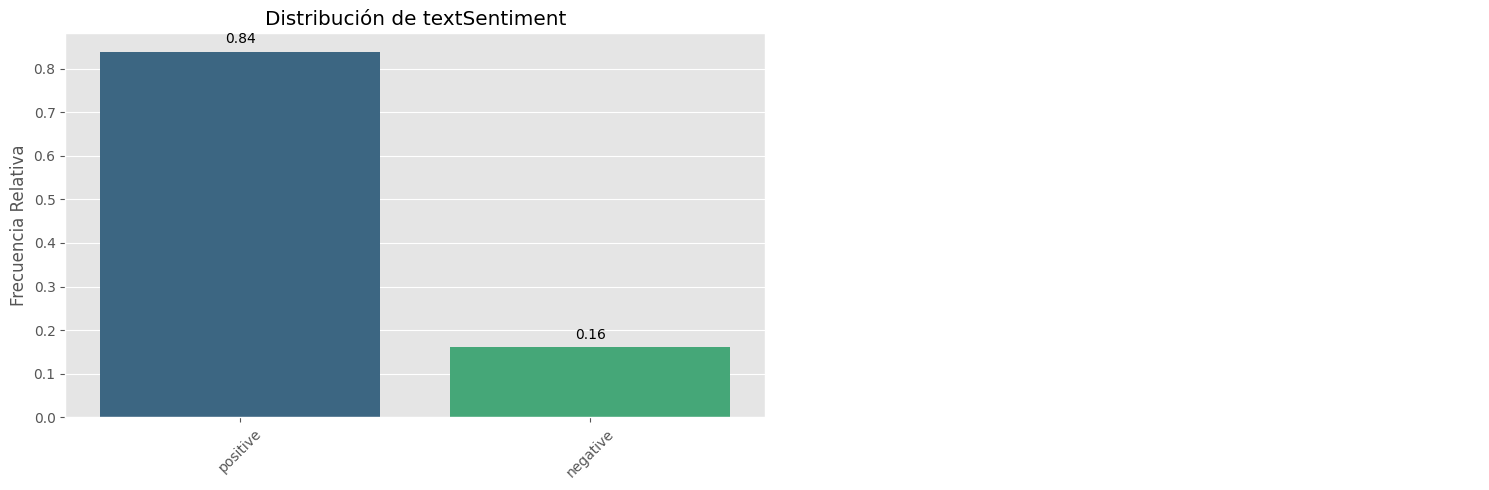

In [12]:
bt.pinta_distribucion_categoricas(train_set, features_cat, relativa = True, mostrar_valores = True)

*Tendremos que convertirla a un valor numérico, como es binaria lo haremos a 0 y 1 (0 para negative, 1 para positive) aunque podríamos haber empleado un one-hot encoding, aquí sí podemos suponer cierto "orden"*

### Ejercicio 7

En un modelado completo habríamos comprobado la relación entre las features y el target; para estos ejercicios, las vamos a incluir sí o sí. Haz el tratamiento de features, haciendo la conversión ordinal de la binaria (usa 1 para positive y 0 para negative) y aplicando el escalado que creas más conveniente en consecuencia para las numéricas

*Convertimos en 0 y 1 la categórica*

In [13]:
train_set["textSentiment"] = train_set["textSentiment"].apply(lambda row: 1 if row == "positive" else 0)
test_set["textSentiment"] = test_set["textSentiment"].apply(lambda row: 1 if row == "positive" else 0)

*El escalado lo vamos a hacer con MinMaxScaler porque ya que hemos convertido la binaria en 0 y 1 el rango será similar. Ojo, en un KNN una conversión ordinal impacta bastante y después de hacerla puede ser posible que aún tuvieras que hacer un escalado a los valores obtenidos*

In [14]:
minmax= MinMaxScaler()
train_set[features_num] = minmax.fit_transform(train_set[features_num])
test_set[features_num] = minmax.transform(test_set[features_num]) # Observa que, al igual que hacemos con el StandardScaler, el fit solo es a train y no otra vez a test (solo usamos transform)
 

*Ojo: el MinMaxScaler no presupone normalidad, pero tampoco corrige la asimetría. En `wordcount`, con un máximo de 103 palabras y la mayoría de reviews por debajo de 15, casi todos los valores quedan apelotonados cerca de 0 tras escalar. Una transformación logarítmica previa, como decíamos antes, podría ayudar al KNN: pruébalo como extra*

### Ejercicio 8

Crea el juego X,y de train y test. Carga el modelo, instáncialo con un k=5 para empezar y entrénalo.

*Creamos los juegos de train y test*

In [15]:
X_train = train_set[features_cat + features_num]
y_train = train_set[target]
X_test = test_set[features_cat + features_num]
y_test = test_set[target]

In [16]:
n_neighbors = 5

knn = KNeighborsClassifier(n_neighbors)
knn.fit(X_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[1,2,3,4,5]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### Ejercicio 9

Evalúalo contra el propio train y contra test, ¿qué puedes decir de los resultados?

*Utilizamos el classification report que nos va a dar todas las medidas interesantes incluyendo las promediadas (macro) y las ponderadas por el número de instancias de cada clase (weighted)*

In [17]:
print(classification_report(y_train, knn.predict(X_train)))

              precision    recall  f1-score   support

           1       0.93      0.96      0.95        27
           2       0.95      0.86      0.90        22
           3       0.88      0.94      0.91        64
           4       0.94      0.74      0.83        23
           5       0.94      0.97      0.96        69

    accuracy                           0.92       205
   macro avg       0.93      0.89      0.91       205
weighted avg       0.92      0.92      0.92       205



In [18]:
print(classification_report(y_test, knn.predict(X_test)))

              precision    recall  f1-score   support

           1       0.82      0.90      0.86        10
           2       0.50      1.00      0.67         2
           3       0.86      0.86      0.86        14
           4       1.00      0.43      0.60         7
           5       0.90      0.95      0.92        19

    accuracy                           0.85        52
   macro avg       0.82      0.83      0.78        52
weighted avg       0.87      0.85      0.84        52



*Es un modelo que en general parece generalizar relativamente bien, salvo quizá respecto al rating 4, en el que el modelo se equivoca poco cuando lo predice (precision alta) pero se deja muchos sin detectar (recall bajo), y el rating 2, donde ocurre lo contrario. Ojo: el test es muy pequeño (52 reviews, solo 2 de rating 2), así que estas métricas por clase son muy inestables. En términos de recall medio parece bastante interesante, pero sería bueno ver cómo le sentaría aplicar alguna de las técnicas de balanceado. Eso sí, al tiempo que probamos otros valores de k*

### Ejercicio 10

Vamos a "ajustar a mano" el valor de K, probando diferentes valores entre 1 y 20. Para ello haz un bucle que cambie el valor de K y obtenga mediante validación cruzada el valor del "balanced accuracy" para cada "modelo" y se quede con el k que mejor métrica obtenga. Luego entrena un modelo para ese k y evalúalo contra test.

In [19]:
metricas = []
for k in range(1,21):
    print(f"Para k= {k}, recall medio:", end = " ")
    model = KNeighborsClassifier(n_neighbors= k)
    balanced_accuracy = np.mean(cross_val_score(model,X_train,y_train, cv = 5, scoring= "balanced_accuracy", n_jobs = -1))
    metricas.append(balanced_accuracy)
    print(balanced_accuracy)
best_k = np.argmax(metricas) + 1 # Guardo el hiperparámetro óptimo para luego entrenar el mejor modelo
print(f"best_k {best_k}")    



Para k= 1, recall medio: 

0.8507179487179487
Para k= 2, recall medio: 

0.8575824175824176
Para k= 3, recall medio: 0.8667765567765567
Para k= 4, recall medio: 0.8561758241758242
Para k= 5, recall medio: 0.8522637362637362
Para k= 6, recall medio: 

0.8291868131868132
Para k= 7, recall medio: 0.8422637362637364
Para k= 8, recall medio: 0.8242637362637362
Para k= 9, recall medio: 0.7974065934065935
Para k= 10, recall medio: 

0.8002637362637361
Para k= 11, recall medio: 0.793120879120879
Para k= 12, recall medio: 0.7822637362637362
Para k= 13, recall medio: 0.7822637362637362
Para k= 14, recall medio: 0.7853406593406594
Para k= 15, recall medio: 

0.7724835164835164
Para k= 16, recall medio: 0.7542637362637363
Para k= 17, recall medio: 0.7544835164835165
Para k= 18, recall medio: 0.7544835164835165
Para k= 19, recall medio: 

0.7464835164835165
Para k= 20, recall medio: 0.7484835164835164
best_k 3


In [20]:
best_model = KNeighborsClassifier(n_neighbors= best_k)
best_model.fit(X_train, y_train)
print(classification_report(y_test, best_model.predict(X_test)))

              precision    recall  f1-score   support

           1       0.80      0.80      0.80        10
           2       0.40      1.00      0.57         2
           3       1.00      0.86      0.92        14
           4       1.00      0.43      0.60         7
           5       0.86      1.00      0.93        19

    accuracy                           0.85        52
   macro avg       0.81      0.82      0.76        52
weighted avg       0.89      0.85      0.84        52



*Un punto interesante para comentar es el que puedes observar comparando estos resultados contra los de test del modelo entrenado con k=5. ¿No deberíamos quedarnos con k=5? No, el set de test es un examen para hacernos a la idea de cómo puede generalizar nuestro modelo y cómo se comportará ante datos nuevos, pero claro, es solo un set de los muchísimos posibles que podremos encontrarnos en el futuro, es por lo que comparar modelos entre sí por su puntuación en el set de test es menos fiable que compararlos usando la validación cruzada donde en realidad se hace una media de tantas pruebas o tantos "test" como k-folds hayamos definido en el parámetro cv. La evaluación contra test del modelo definitivo sirve para "gestionar" nuestras expectativas del comportamiento futuro*

### Ejercicio 11

Repasa la ficha de KNN o la documentación de sklearn y, usando un grid y una estrategia completa (GridSearch), busca la mejor combinación de k y weights que puedas, empleando de nuevo "balanced_accuracy" como métrica.

In [21]:
param_grid = {
    "n_neighbors": range(1,21),
    "weights": ["uniform","distance"]
}

knn_grid = GridSearchCV(knn, 
                        param_grid = param_grid,
                        cv = 5,
                        scoring = "balanced_accuracy",
                        n_jobs = -1)

knn_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': range(1, 21), 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of 

In [22]:
knn_grid.best_params_

{'n_neighbors': 3, 'weights': 'uniform'}

In [23]:
knn_grid.best_score_

0.8667765567765567

In [24]:
print(classification_report(y_test, knn_grid.best_estimator_.predict(X_test)))

              precision    recall  f1-score   support

           1       0.80      0.80      0.80        10
           2       0.40      1.00      0.57         2
           3       1.00      0.86      0.92        14
           4       1.00      0.43      0.60         7
           5       0.86      1.00      0.93        19

    accuracy                           0.85        52
   macro avg       0.81      0.82      0.76        52
weighted avg       0.89      0.85      0.84        52



*Pues igual que usando nuestro método "casero" y "manual", pero eso no quiere decir que en otras circunstancias y otro dataset hubiera sido equivalente. Si te fijas "uniform" (que aporten todos los "vecinos" por igual) es el valor por defecto de weights*